In [ ]:
import pandas as pd

df = pd.read_csv("C:\\saas1\\despesas-domesticas\\data\\despesas_familia.csv", parse_dates=["data"])

In [2]:
df.head()

,id,data,ano,mes,descricao,estabelecimento,categoria,subcategoria,valor,forma_pagamento,tipo_despesa,essencial,responsavel
0,1,2023-10-01,2023,10,Seguro do carro (parcela),Porto Seguro,Transporte,Seguro auto,285.00,Cartão de crédito,Fixa,Sim,Pai
1,2,2023-10-02,2023,10,Compras de supermercado,Supermercado Bom Preço,Alimentação,Supermercado,190.13,Pix,Variável,Sim,Casal
2,3,2023-10-03,2023,10,Padaria,Padaria Pão Quente,Alimentação,Padaria,35.86,Cartão de débito,Variável,Sim,Mãe
3,4,2023-10-03,2023,10,Streaming de vídeo,Netflix,Lazer,Assinaturas,39.90,Cartão de crédito,Fixa,Não,Casal
4,5,2023-10-04,2023,10,Medicamentos,Farmácia,Saúde,Farmácia,190.49,Cartão de crédito,Variável,Sim,Pai


In [3]:
df.shape

(1439, 13)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1439 entries, 0 to 1438
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id               1439 non-null   int64         
 1   data             1439 non-null   datetime64[us]
 2   ano              1439 non-null   int64         
 3   mes              1439 non-null   int64         
 4   descricao        1439 non-null   str           
 5   estabelecimento  1439 non-null   str           
 6   categoria        1439 non-null   str           
 7   subcategoria     1439 non-null   str           
 8   valor            1439 non-null   float64       
 9   forma_pagamento  1439 non-null   str           
 10  tipo_despesa     1439 non-null   str           
 11  essencial        1439 non-null   str           
 12  responsavel      1439 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(3), str(8)
memory usage: 260.3 KB


In [5]:
df["valor"].describe()

count    1439.000000
mean      329.540528
std       529.875740
min        14.510000
25%        70.760000
50%       151.680000
75%       285.000000
max      4458.830000
Name: valor, dtype: float64

In [6]:
df["categoria"].unique()

<ArrowStringArray>
[       'Transporte',       'Alimentação',             'Lazer',
             'Saúde',           'Moradia',          'Educação',
              'Pets',       'Comunicação',         'Vestuário',
           'Compras', 'Cuidados pessoais',         'Presentes',
           'Viagens']
Length: 13, dtype: str

In [7]:
df["categoria"].nunique()

13

In [8]:
df["valor"].sum()

np.float64(474208.82)

In [9]:
total_cat = df.groupby("categoria")["valor"].sum().sort_values(ascending=False)
total_cat

categoria
Moradia              133560.20
Educação              76657.38
Saúde                 69560.95
Alimentação           62391.05
Transporte            47034.82
Viagens               22794.41
Compras               11998.11
Presentes             11205.30
Comunicação            9869.16
Lazer                  9650.55
Pets                   8960.77
Vestuário              7169.01
Cuidados pessoais      3357.11
Name: valor, dtype: float64

In [10]:
pct_cat = (total_cat / total_cat.sum() * 100).round(1)
pct_cat

categoria
Moradia              28.2
Educação             16.2
Saúde                14.7
Alimentação          13.2
Transporte            9.9
Viagens               4.8
Compras               2.5
Presentes             2.4
Comunicação           2.1
Lazer                 2.0
Pets                  1.9
Vestuário             1.5
Cuidados pessoais     0.7
Name: valor, dtype: float64

In [11]:
pct_cat.head(3).sum().round(1)

np.float64(59.1)

In [12]:
resumo = (
    df.groupby("categoria")["valor"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
      .round(2)
)
resumo

,sum,mean,count
categoria,,,
Moradia,133560.20,627.04,213
Educação,76657.38,1022.10,75
Saúde,69560.95,709.81,98
Alimentação,62391.05,139.58,447
Transporte,47034.82,188.14,250
Viagens,22794.41,2532.71,9
Compras,11998.11,1199.81,10
Presentes,11205.30,1245.03,9
Comunicação,9869.16,91.38,108


In [13]:
total_subcat = (
    df.groupby("subcategoria")["valor"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
    .round(2)
    .head(5)
)
total_subcat

,sum,mean,count
subcategoria,,,
Aluguel,83226.00,2311.83,36
Plano de saúde,57039.00,1584.42,36
Mensalidade escolar,56627.56,1572.99,36
Supermercado,35784.09,197.70,181
Combustível,21237.87,194.84,109


In [14]:
total_pag = df.groupby("forma_pagamento")["valor"].agg(["sum", "count"]).sort_values("sum", ascending=False)
total_pag

,sum,count
forma_pagamento,,
Boleto,241611.01,192
Cartão de crédito,143318.59,686
Pix,49504.01,305
Cartão de débito,26317.42,184
Débito automático,13457.79,72


In [15]:
pct_pag = (total_pag / total_pag.sum() * 100).round(1)
pct_pag

,sum,count
forma_pagamento,,
Boleto,51.0,13.3
Cartão de crédito,30.2,47.7
Pix,10.4,21.2
Cartão de débito,5.5,12.8
Débito automático,2.8,5.0


In [16]:
df["ano_mes"] = df["data"].dt.to_period("M")
df[["data", "ano_mes"]].head()

,data,ano_mes
0,2023-10-01,2023-10
1,2023-10-02,2023-10
2,2023-10-03,2023-10
3,2023-10-03,2023-10
4,2023-10-04,2023-10


In [17]:
gasto_mensal = df.groupby("ano_mes")["valor"].sum()
gasto_mensal

ano_mes
2023-10     9991.24
2023-11    12658.36
2023-12    12575.40
2024-01    11161.63
2024-02    12313.41
2024-03    13842.92
2024-04    11160.68
2024-05    11227.45
2024-06    11531.86
2024-07    18962.30
2024-08    12003.43
2024-09     9754.10
2024-10    11903.91
2024-11    13375.14
2024-12    14372.57
2025-01    12092.77
2025-02    14193.38
2025-03    14084.59
2025-04    10734.49
2025-05    14223.50
2025-06    11030.35
2025-07    19751.42
2025-08    12509.07
2025-09    15471.98
2025-10    11314.27
2025-11    12837.92
2025-12    15481.62
2026-01    12554.30
2026-02    16549.66
2026-03    13382.37
2026-04    11860.40
2026-05    12200.16
2026-06    12111.26
2026-07    19100.68
2026-08    13474.22
2026-09    12416.01
Freq: M, Name: valor, dtype: float64

In [18]:
gasto_mensal.sort_values(ascending=False).head(5)

ano_mes
2025-07    19751.42
2026-07    19100.68
2024-07    18962.30
2026-02    16549.66
2025-12    15481.62
Freq: M, Name: valor, dtype: float64

In [19]:
gasto_mensal.idxmax()

Period('2025-07', 'M')

In [20]:
gasto_mensal.idxmin()

Period('2024-09', 'M')

In [21]:
gasto_anual = df.groupby("ano")["valor"].sum()
gasto_anual

ano
2023     35225.00
2024    151609.40
2025    163725.36
2026    123649.06
Name: valor, dtype: float64

In [22]:
media_mensal = (gasto_anual / df.groupby("ano")["ano_mes"].nunique()).round(2)
media_mensal

ano
2023    11741.67
2024    12634.12
2025    13643.78
2026    13738.78
dtype: float64

In [23]:
media_mensal[2025]/media_mensal[2024]

np.float64(1.07991534036403)

In [24]:
pivot = df.pivot_table(
    index="ano",
    columns="categoria",
    values="valor",
    aggfunc="sum",
    fill_value=0
)
pivot.round(0)

categoria,Alimentação,Compras,Comunicação,Cuidados pessoais,Educação,Lazer,Moradia,Pets,Presentes,Saúde,Transporte,Vestuário,Viagens
ano,,,,,,,,,,,,,
2023,5326.0,2193.0,779.0,228.0,5400.0,619.0,10721.0,512.0,1372.0,5479.0,2120.0,475.0,0.0
2024,20745.0,5082.0,3159.0,1012.0,23970.0,3573.0,42905.0,2119.0,3333.0,20652.0,14476.0,2773.0,7811.0
2025,21083.0,4722.0,3332.0,1273.0,26063.0,2994.0,45231.0,3743.0,4119.0,23629.0,17463.0,1725.0,8349.0
2026,15236.0,0.0,2600.0,844.0,21225.0,2464.0,34704.0,2587.0,2381.0,19802.0,12977.0,2196.0,6634.0


In [25]:
tipo = df.groupby("tipo_despesa")["valor"].sum()
tipo

tipo_despesa
Fixa        282729.65
Variável    191479.17
Name: valor, dtype: float64

In [26]:
essen = df.groupby("essencial")["valor"].sum()
essen

essencial
Não    116710.18
Sim    357498.64
Name: valor, dtype: float64

In [27]:
print((tipo / tipo.sum() * 100).round(1))
print((essen / essen.sum() * 100).round(1))

tipo_despesa
Fixa        59.6
Variável    40.4
Name: valor, dtype: float64
essencial
Não    24.6
Sim    75.4
Name: valor, dtype: float64


In [28]:
df.pivot_table(
    index="tipo_despesa",
    columns="essencial",
    values="valor",
    aggfunc="sum",
).round(0)

essencial,Não,Sim
tipo_despesa,,
Fixa,37155.0,245575.0
Variável,79555.0,111924.0


In [29]:
por_tipo = df.pivot_table(
    index="ano_mes",
    columns="tipo_despesa",
    values="valor",
    aggfunc="sum"
)

por_tipo.agg(["mean", "std"]).round(2)

tipo_despesa,Fixa,Variável
mean,7853.60,5318.87
std,571.48,2338.79


In [30]:
superfluos = df[df["essencial"] == "Não"]
superfluos.groupby("categoria")["valor"].sum().sort_values(ascending=False)

categoria
Viagens              22794.41
Alimentação          17660.53
Educação             16687.16
Moradia              12105.60
Presentes            11205.30
Lazer                 9650.55
Compras               8708.11
Vestuário             7169.01
Saúde                 4491.36
Cuidados pessoais     3357.11
Transporte            2881.04
Name: valor, dtype: float64

In [31]:
superfluos[superfluos["categoria"] == "Alimentação"]["subcategoria"].value_counts()

subcategoria
Restaurantes e delivery    116
Datas especiais              3
Name: count, dtype: int64

In [32]:
superfluos

,id,data,ano,mes,descricao,estabelecimento,categoria,subcategoria,valor,forma_pagamento,tipo_despesa,essencial,responsavel,ano_mes
3,4,2023-10-03,2023,10,Streaming de vídeo,Netflix,Lazer,Assinaturas,39.90,Cartão de crédito,Fixa,Não,Casal,2023-10
6,7,2023-10-05,2023,10,Mensalidade de inglês,Escola de Idiomas,Educação,Cursos,420.00,Boleto,Fixa,Não,Filho 2,2023-10
8,9,2023-10-06,2023,10,Academia,SmartFit,Saúde,Academia,119.90,Cartão de crédito,Fixa,Não,Mãe,2023-10
10,11,2023-10-07,2023,10,Streaming de música,Spotify,Lazer,Assinaturas,34.90,Cartão de crédito,Fixa,Não,Filho 1,2023-10
21,22,2023-10-15,2023,10,Corrida de aplicativo,Uber,Transporte,Aplicativo,26.90,Cartão de crédito,Variável,Não,Mãe,2023-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1422,1423,2026-09-14,2026,9,Streaming de filmes e séries,Max,Lazer,Assinaturas,34.90,Cartão de crédito,Fixa,Não,Casal,2026-09
1428,1429,2026-09-18,2026,9,Jogo de videogame,Sympla,Lazer,Entretenimento,248.97,Cartão de crédito,Variável,Não,Filho 1,2026-09
1431,1432,2026-09-20,2026,9,Delivery,iFood,Alimentação,Restaurantes e delivery,158.94,Cartão de crédito,Variável,Não,Casal,2026-09
1434,1435,2026-09-23,2026,9,Delivery,Restaurante Sabor,Alimentação,Restaurantes e delivery,124.44,Cartão de crédito,Variável,Não,Mãe,2026-09


In [33]:
superfluos_mensal = superfluos.groupby("ano_mes")["valor"].sum()
superfluos_mensal

ano_mes
2023-10     1865.95
2023-11     3873.09
2023-12     3911.66
2024-01     1675.61
2024-02     1888.82
2024-03     4473.91
2024-04     2374.83
2024-05     2404.20
2024-06     2671.83
2024-07    10663.67
2024-08     3190.80
2024-09     1328.07
2024-10     2455.55
2024-11     3866.50
2024-12     4758.05
2025-01     1938.65
2025-02     1899.25
2025-03     3622.55
2025-04     1816.87
2025-05     2386.10
2025-06     1514.54
2025-07    10161.97
2025-08     2482.53
2025-09     2010.40
2025-10     1636.33
2025-11     3330.79
2025-12     4560.48
2026-01     1916.14
2026-02     2447.87
2026-03     2602.63
2026-04     1513.77
2026-05     2442.37
2026-06     2400.08
2026-07     8894.76
2026-08     3324.13
2026-09     2405.43
Freq: M, Name: valor, dtype: float64

In [34]:
superfluos_anual = superfluos.groupby("ano")["valor"].sum()
superfluos_anual

ano
2023     9650.70
2024    41751.84
2025    37360.46
2026    27947.18
Name: valor, dtype: float64

In [35]:
superfluos_media_mensal = superfluos_anual / superfluos.groupby("ano")["ano_mes"].nunique()
superfluos_media_mensal

ano
2023    3216.900000
2024    3479.320000
2025    3113.371667
2026    3105.242222
dtype: float64

In [36]:
3113.37 / 3479.32

0.8948214018831265

In [37]:
import matplotlib.pyplot as plt

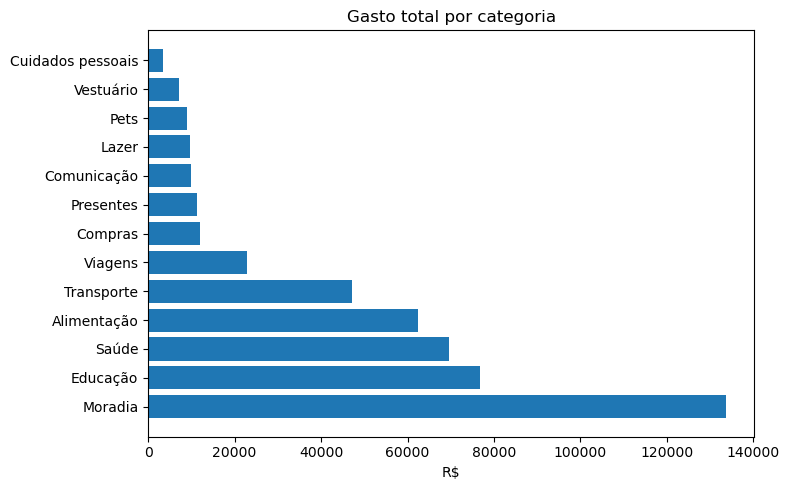

In [38]:
# gráfico de barras horizontais - gastos por categoria
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(total_cat.index, total_cat.values)
ax.set_title("Gasto total por categoria")
ax.set_xlabel("R$")
plt.tight_layout()
plt.show()

In [39]:
fig.savefig("grafico-barras-h.png", dpi=150, bbox_inches="tight")

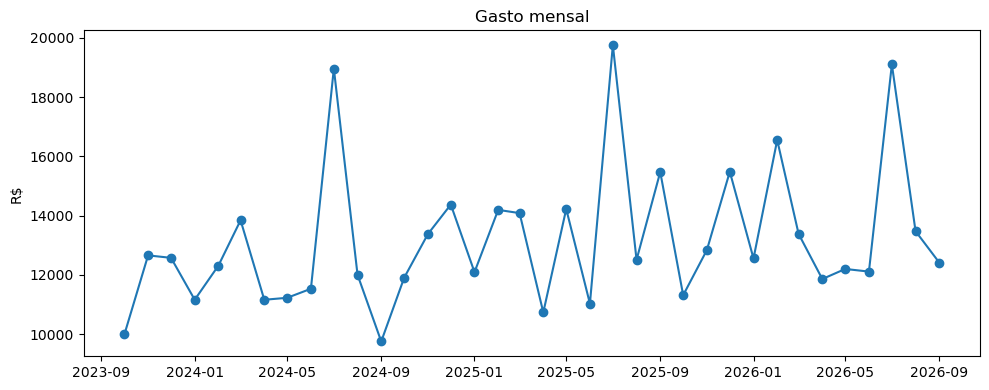

In [40]:
# gráfico de linha - evolução mensal

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(gasto_mensal.index.to_timestamp(), gasto_mensal.values, marker="o")
ax.set_title("Gasto mensal")
ax.set_ylabel("R$")
plt.tight_layout()
plt.show()

In [41]:
fig.savefig("grafico-linhas.png", dpi=150, bbox_inches="tight")

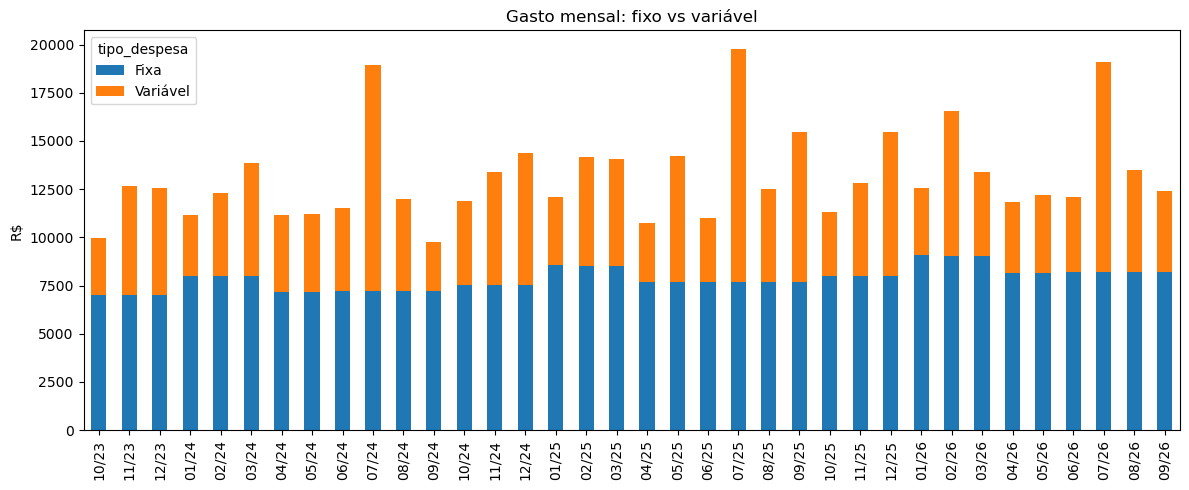

In [42]:
# barras empilhadas - fixo vs. variável

por_tipo = df.pivot_table(
    index="ano_mes", columns="tipo_despesa",
    values="valor", aggfunc="sum"
)
por_tipo.index = por_tipo.index.strftime("%m/%y")

ax = por_tipo.plot(kind="bar", stacked=True, figsize=(12, 5),
                   title="Gasto mensal: fixo vs variável")
ax.set_xlabel("")
ax.set_ylabel("R$")
plt.tight_layout()
plt.show()

In [43]:
fig.savefig("grafico-barras-e.png", dpi=150, bbox_inches="tight")

In [44]:
gasto_saude_mensal = df[df["categoria"] == "Saúde"].groupby("ano_mes")["valor"].sum()
gasto_saude_anual = df[df["categoria"] == "Saúde"].groupby("ano")["valor"].sum()
gasto_saude_anual

ano
2023     5478.60
2024    20651.56
2025    23628.82
2026    19801.97
Name: valor, dtype: float64

In [45]:
gasto_saude_media_mensal = gasto_saude_anual / df[df["categoria"] == "Saúde"].groupby("ano")["ano_mes"].nunique()
gasto_saude_media_mensal

ano
2023    1826.200000
2024    1720.963333
2025    1969.068333
2026    2200.218889
dtype: float64

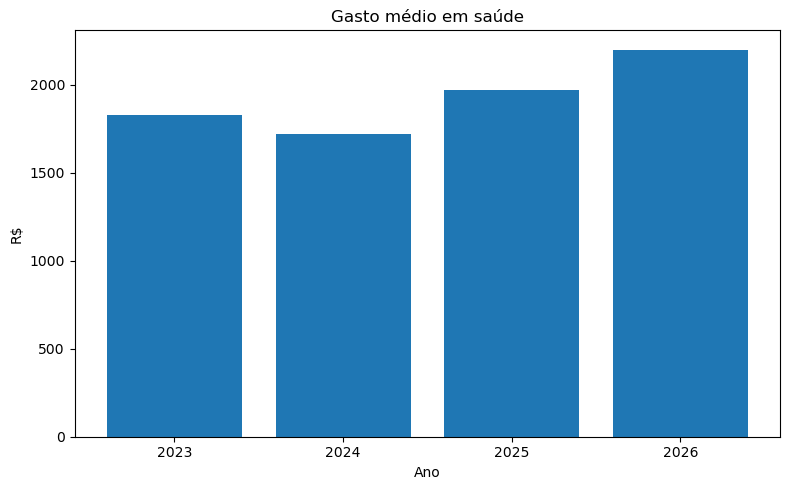

In [46]:
# barras verticais - gasto saude

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(gasto_saude_media_mensal.index.astype(str), gasto_saude_media_mensal.values)
ax.set_title("Gasto médio em saúde")
ax.set_xlabel("Ano")
ax.set_ylabel("R$")
plt.tight_layout()
plt.show()

In [47]:
fig.savefig("grafico-barras-v.png", dpi=150, bbox_inches="tight")

In [48]:
# Análise da inflação nos gastos (tava de 4,5%)
taxa = 0.045

dias = (df["data"] - df["data"].min()).dt.days
df["valor_real"] = df["valor"] / ((1 + taxa) ** (dias / 365))
df[["valor_real", "valor"]].head(10)

,valor_real,valor
0,285.000000,285.00
1,190.107073,190.13
2,35.851352,35.86
3,39.890378,39.90
4,190.421096,190.49
5,2198.939027,2200.00
6,419.797451,420.00
7,1379.334481,1380.00
8,119.827726,119.90
9,62.944439,62.99


In [49]:
medias = (
    df.groupby("ano")[["valor", "valor_real"]].sum()
      .div(df.groupby("ano")["ano_mes"].nunique(), axis=0)
)
medias.round(0)



,valor,valor_real
ano,,
2023,11742.0,11681.0
2024,12634.0,12226.0
2025,13644.0,12636.0
2026,13739.0,12247.0


In [50]:
(medias.pct_change() * 100).round(1)

,valor,valor_real
ano,,
2023,NaN,NaN
2024,7.6,4.7
2025,8.0,3.3
2026,0.7,-3.1


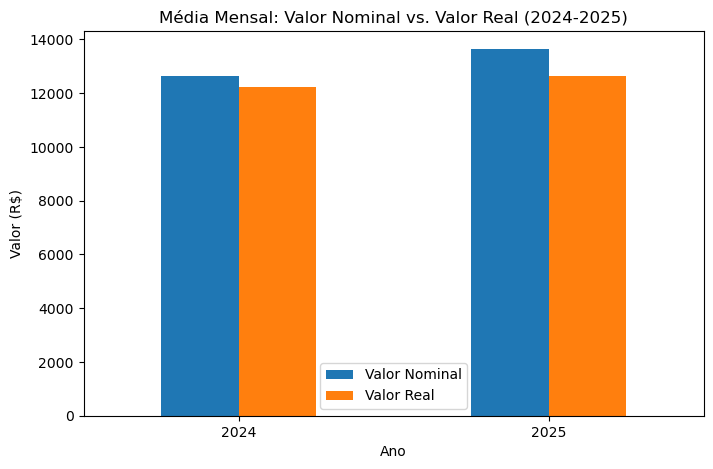

In [51]:
ax = medias.loc[[2024, 2025]].plot(kind="bar", figsize=(8, 5))
plt.title("Média Mensal: Valor Nominal vs. Valor Real (2024-2025)")
plt.xlabel("Ano")
plt.ylabel("Valor (R$)")
plt.xticks(rotation=0)  # Deixa os anos "2024" e "2025" retos no eixo X
plt.legend(["Valor Nominal", "Valor Real"])  # Personaliza a legenda das barras

plt.show()

In [52]:
# Quem gasta mais?

resp = df.groupby("responsavel")["valor"].agg(["sum", "count", "mean"]).sort_values("sum", ascending=False)
resp["pct"] = resp["sum"] / resp["sum"].sum() * 100
resp.round(1)


,sum,count,mean,pct
responsavel,,,,
Casal,276670.4,588,470.5,58.3
Filho 1,81293.5,179,454.2,17.1
Pai,58168.2,308,188.9,12.3
Filho 2,35022.8,107,327.3,7.4
Mãe,23054.0,257,89.7,4.9


In [53]:
ind = df[df["responsavel"] != "Casal"]

ind.pivot_table(
    index="categoria",
    columns="responsavel",
    values="valor",
    aggfunc="sum",
    fill_value=0
).round(0)

responsavel,Filho 1,Filho 2,Mãe,Pai
categoria,,,,
Alimentação,3681.0,0.0,10634.0,6262.0
Compras,3900.0,0.0,0.0,0.0
Comunicação,0.0,0.0,2644.0,2644.0
Cuidados pessoais,0.0,0.0,1354.0,2003.0
Educação,59970.0,16687.0,0.0,0.0
Lazer,3091.0,2423.0,0.0,0.0
Pets,0.0,8961.0,0.0,0.0
Presentes,4046.0,2513.0,0.0,0.0
Saúde,2931.0,1808.0,5922.0,1862.0


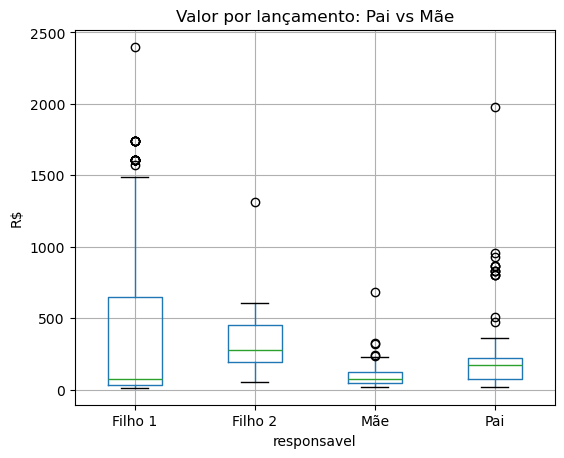

In [54]:
pm = df[df["responsavel"].isin(["Pai", "Mãe"])]

ax = ind.boxplot(column="valor", by="responsavel", figsize=(6, 5))
plt.suptitle("")
ax.set_title("Valor por lançamento: Pai vs Mãe")
ax.set_ylabel("R$")
plt.show()

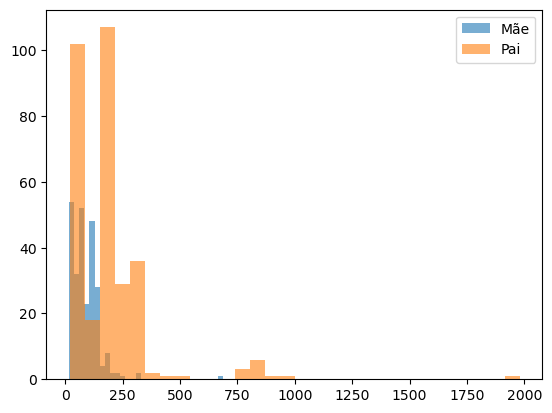

In [55]:
fig, ax = plt.subplots()
for nome, grupo in pm.groupby("responsavel"):
    ax.hist(grupo["valor"], bins=30, alpha=0.6, label=nome)
ax.legend()
plt.show()

In [56]:
pivot_forma_pagamento = df.pivot_table(
    index="ano",
    columns="forma_pagamento",
    values="valor",
    aggfunc="sum",
    fill_value=0
)

pivot_forma_pagamento.round(1)

forma_pagamento,Boleto,Cartão de crédito,Cartão de débito,Débito automático,Pix
ano,,,,,
2023,17915.8,10167.4,1961.9,1052.9,4127.0
2024,76631.8,48362.7,7724.4,4358.2,14532.2
2025,81703.6,48852.0,8872.0,4546.0,19751.8
2026,65359.7,35936.5,7759.1,3500.7,11093.0


In [57]:
pct_forma = pivot_forma_pagamento.div(pivot_forma_pagamento.sum(axis=1), axis=0) * 100
pct_forma.round(1)

forma_pagamento,Boleto,Cartão de crédito,Cartão de débito,Débito automático,Pix
ano,,,,,
2023,50.9,28.9,5.6,3.0,11.7
2024,50.5,31.9,5.1,2.9,9.6
2025,49.9,29.8,5.4,2.8,12.1
2026,52.9,29.1,6.3,2.8,9.0


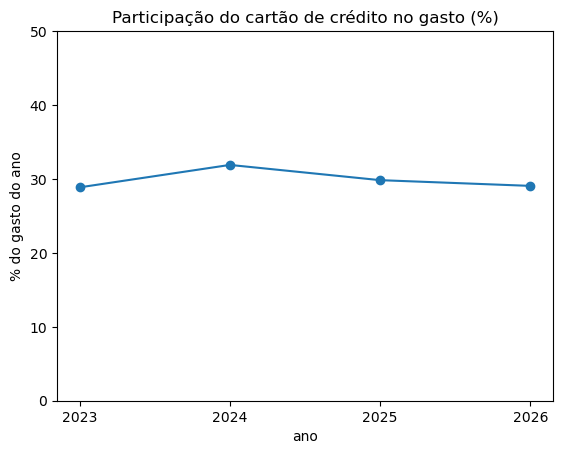

In [58]:
ax = pct_forma["Cartão de crédito"].plot(marker="o", title="Participação do cartão de crédito no gasto (%)")
ax.set_xticks(pct_forma.index)
ax.set_ylabel("% do gasto do ano")
ax.set_ylim(0, 50)
plt.show()

In [59]:
pivot_forma_pagamento_ano_mes = df.pivot_table(
    index="ano_mes",
    columns="forma_pagamento",
    values="valor",
    aggfunc="sum",
    fill_value=0
)

pivot_forma_pagamento_ano_mes.round(1)

forma_pagamento,Boleto,Cartão de crédito,Cartão de débito,Débito automático,Pix
ano_mes,,,,,
2023-10,5970.0,2087.0,98.8,340.5,1494.9
2023-11,5972.0,4006.6,1266.0,342.9,1071.0
2023-12,5973.8,4073.9,597.1,369.5,1561.1
2024-01,6955.8,2110.8,875.5,391.4,828.1
2024-02,6913.4,3481.3,287.2,411.4,1220.2
2024-03,6915.2,5469.6,183.2,412.1,862.8
2024-04,6117.2,2557.7,903.7,345.0,1237.1
2024-05,6119.1,3295.8,605.0,318.4,889.0
2024-06,6121.1,3397.5,498.1,319.2,1196.0


In [60]:
pct_forma_ano_mes = pivot_forma_pagamento_ano_mes.div(pivot_forma_pagamento_ano_mes.sum(axis=1), axis=0) * 100
pct_forma_ano_mes.round(1)

forma_pagamento,Boleto,Cartão de crédito,Cartão de débito,Débito automático,Pix
ano_mes,,,,,
2023-10,59.8,20.9,1.0,3.4,15.0
2023-11,47.2,31.7,10.0,2.7,8.5
2023-12,47.5,32.4,4.7,2.9,12.4
2024-01,62.3,18.9,7.8,3.5,7.4
2024-02,56.1,28.3,2.3,3.3,9.9
2024-03,50.0,39.5,1.3,3.0,6.2
2024-04,54.8,22.9,8.1,3.1,11.1
2024-05,54.5,29.4,5.4,2.8,7.9
2024-06,53.1,29.5,4.3,2.8,10.4


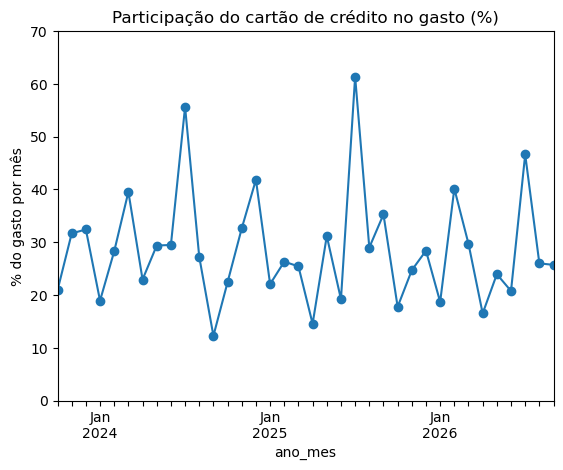

In [61]:
ax = pct_forma_ano_mes["Cartão de crédito"].plot(marker="o", title="Participação do cartão de crédito no gasto (%)")
ax.set_xticks(pct_forma_ano_mes.index)
ax.set_ylabel("% do gasto por mês")
ax.set_ylim(0, 70)
plt.show()

In [62]:
pct_forma_ano_mes["Cartão de crédito"].idxmax()

Period('2025-07', 'M')

In [63]:
pct_forma_ano_mes["Cartão de crédito"].max()

61.353158405826015

In [64]:
julho = df[df["ano_mes"] == "2025-07"]
julho.groupby("categoria")["valor"].sum().sort_values(ascending=False)

categoria
Viagens              8349.03
Moradia              3540.09
Educação             2081.54
Saúde                1887.59
Alimentação          1826.94
Transporte           1177.38
Lazer                 377.79
Comunicação           273.89
Pets                  167.06
Cuidados pessoais      70.11
Name: valor, dtype: float64

In [65]:
julho[julho["forma_pagamento"] == "Cartão de crédito"].groupby("categoria")["valor"].sum().sort_values(ascending=False)

categoria
Viagens        8349.03
Alimentação    1465.88
Transporte     1177.38
Lazer           377.79
Saúde           307.09
Comunicação     273.89
Pets            167.06
Name: valor, dtype: float64

In [66]:
julho[julho["categoria"] == "Viagens"][["descricao", "valor", "forma_pagamento", "valor_real"]]

,descricao,valor,forma_pagamento,valor_real
848,Passeios e alimentação na viagem,1334.32,Cartão de crédito,1233.721936
849,Viagem de férias (passagens/gasolina),2555.88,Cartão de crédito,2363.185159
859,Viagem de férias (hospedagem),4458.83,Cartão de crédito,4121.175272


In [67]:
pct_forma_ano_mes["Cartão de crédito"].idxmin()

Period('2024-09', 'M')

In [68]:
pct_forma_ano_mes["Cartão de crédito"].min()

12.253616427963628

In [69]:
setembro = df[df['ano_mes'] == "2024-09"]
setembro.groupby("categoria")["valor"].sum().sort_values(ascending=False)

categoria
Moradia        3396.73
Educação       1935.60
Saúde          1801.29
Alimentação    1067.65
Transporte     1012.22
Comunicação     259.70
Pets            171.21
Lazer           109.70
Name: valor, dtype: float64

In [70]:
setembro[setembro["forma_pagamento"] == "Cartão de crédito"].groupby("categoria")["valor"].sum().sort_values(ascending=False)

categoria
Transporte     437.72
Comunicação    259.70
Pets           171.21
Saúde          119.90
Lazer          109.70
Alimentação     97.00
Name: valor, dtype: float64